# Türkiye Üniversiteleri Arası Bilimsel İş Birliği Ağı
## Sosyal Ağ Analizi — Final Raporu ve İleri Analiz Hattı (30 Ekim 2026)

**Kurum:** Manisa Celal Bayar Üniversitesi — Büyük Veri Analistliği
**Proje Kapsamı:** OpenAlex 2020–2025 dönemi Türkiye Bilgisayar Bilimi (Computer Science) yayınları üzerinden kurumsal iş birliği ağı.

Bu notebook, 30 Ekim 2026 final teslim ödev kartında tanımlanan tüm analiz adımlarını modüler betikler (`scripts/`) aracılığıyla baştan sona çalıştırır ve sonuçları görselleştirir:
1. **Temel Ağ Ölçüleri ve Merkeziyetler:** Kapsam B1 (186 aktif üniversite, tek bileşen) ve Kapsam B (194 üniversite, duyarlılık analizi), 5 merkeziyet ölçüsü, Spearman korelasyonu.
2. **Derece Dağılımı ve Güç Yasası:** `powerlaw` ile log-log CCDF grafiği, $\alpha, x_{min}$, lognormal ve üstel model karşılaştırmaları.
3. **Louvain ve Leiden Topluluk Tespiti:** 10 farklı sabit tohum ile kararlılık analizi (NMI ve ARI), en büyük toplulukların dökümü.
4. **Null Model Analizi:** Derece dizisini %100 koruyan 100 rastgele ağ ile $C, L, Q$ Z-skorları ve Small-Worldness ($\\sigma$).
5. **Zorunlu İleri Yöntem: Çekim (Gravity) Modeli Regresyonu:** 17.205 ikili çift, Haversine mesafesi ($d_{eff} = d + 1\text{ km}$), Poisson ve Negative Binomial GLM modelleri, aşırı yayılım kontrolü ve Ege Bölgesi çekim etkisi.
6. **Etkileşimli Coğrafi Harita:** Folium ile Türkiye geneli iş birliği haritası ve jitter ayrıştırması.

In [10]:
import os
import sys
import json
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Image

# Proje kök dizinini ekle
sys.path.append(os.path.abspath(".."))

from scripts.run_final_analysis import load_network_data, build_scope_graph
from scripts.analysis_metrics import compute_network_topology, compute_centralities
from scripts.analysis_powerlaw import fit_powerlaw_distribution
from scripts.analysis_community import analyze_communities, SEEDS_10
from scripts.analysis_null_model import run_null_model_experiments
from scripts.analysis_gravity import build_dyadic_dataset, fit_gravity_models
from scripts.visualize_map import generate_collaboration_map

print("Gerekli kütüphaneler ve analiz modülleri başarıyla yüklendi.")

Gerekli kütüphaneler ve analiz modülleri başarıyla yüklendi.


## 1. Veri Yükleme ve Ağ Grafiği İnşası
İşlenmiş kurum metaverileri (`institutions.csv`) ve kenar listesi (`edges.csv`) yüklenir. Analizin ana odağı **Kapsam B1** (186 aktif üniversite) olup, **Kapsam B** (194 üniversite) duyarlılık kıyaslaması için kurulur.

In [11]:
df_inst, df_edges = load_network_data("../data/processed/institutions.csv", "../data/processed/edges.csv")

# Kapsam B1: 186 Aktif Üniversite
G_b1, df_b1 = build_scope_graph(df_inst, df_edges, allowed_categories=["active_university"])

# Kapsam B: 194 Aktif ve Kapatılan Üniversite
G_b, df_b = build_scope_graph(df_inst, df_edges, allowed_categories=["active_university", "closed_2016_khk", "closed_2020_cbk"])

print(f"Scope B1 Düğüm Sayısı: {G_b1.number_of_nodes()}, Kenar Sayısı: {G_b1.number_of_edges()}")
print(f"Scope B  Düğüm Sayısı: {G_b.number_of_nodes()}, Kenar Sayısı: {G_b.number_of_edges()}")

Scope B1 Düğüm Sayısı: 186, Kenar Sayısı: 3848
Scope B  Düğüm Sayısı: 194, Kenar Sayısı: 3887


## 2. Temel Ağ Ölçüleri ve Merkeziyetler
- Düğüm ve kenar sayıları, yoğunluk, kümelenme katsayısı, derece benzeşimi.
- Bağlantısız ağlarda tüm ağ ile dev bağlı bileşen (LCC) ayrımı.
- Degree, Weighted Degree, Betweenness, Closeness ve PageRank merkeziyetleri ile Spearman korelasyonu.

In [12]:
topo_b1 = compute_network_topology(G_b1, scope_name="Scope B1")
topo_b = compute_network_topology(G_b, scope_name="Scope B")

df_topo = pd.DataFrame([
    {
        "Metrik": "Düğüm Sayısı (N)",
        "Scope B1 (Aktif Üniversiteler)": topo_b1["number_of_nodes"],
        "Scope B (Tüm Üniversiteler)": topo_b["number_of_nodes"]
    },
    {
        "Metrik": "Kenar Sayısı (M)",
        "Scope B1 (Aktif Üniversiteler)": topo_b1["number_of_edges"],
        "Scope B (Tüm Üniversiteler)": topo_b["number_of_edges"]
    },
    {
        "Metrik": "Ağ Yoğunluğu (Density)",
        "Scope B1 (Aktif Üniversiteler)": f"{topo_b1["density"]:.4f}",
        "Scope B (Tüm Üniversiteler)": f"{topo_b["density"]:.4f}"
    },
    {
        "Metrik": "Bağlı Bileşen Sayısı",
        "Scope B1 (Aktif Üniversiteler)": topo_b1["number_connected_components"],
        "Scope B (Tüm Üniversiteler)": topo_b["number_connected_components"]
    },
    {
        "Metrik": "İzole Düğüm Sayısı",
        "Scope B1 (Aktif Üniversiteler)": topo_b1["number_isolated_nodes"],
        "Scope B (Tüm Üniversiteler)": topo_b["number_isolated_nodes"]
    },
    {
        "Metrik": "Ortalama Kümelenme (C)",
        "Scope B1 (Aktif Üniversiteler)": f"{topo_b1["average_clustering_coefficient"]:.4f}",
        "Scope B (Tüm Üniversiteler)": f"{topo_b["average_clustering_coefficient"]:.4f}"
    },
    {
        "Metrik": "Derece Benzeşimi (r)",
        "Scope B1 (Aktif Üniversiteler)": f"{topo_b1["degree_assortativity"]:.4f}",
        "Scope B (Tüm Üniversiteler)": f"{topo_b["degree_assortativity"]:.4f}"
    },
    {
        "Metrik": "Ortalama En Kısa Yol (Tüm Ağ)",
        "Scope B1 (Aktif Üniversiteler)": f"{topo_b1["full_network_average_path_length"]:.4f}",
        "Scope B (Tüm Üniversiteler)": "Tanımsız (Bağlantısız Ağ)"
    },
    {
        "Metrik": "LCC Ortalama En Kısa Yol (L)",
        "Scope B1 (Aktif Üniversiteler)": f"{topo_b1["largest_connected_component"]["average_shortest_path_length"]:.4f}",
        "Scope B (Tüm Üniversiteler)": f"{topo_b["largest_connected_component"]["average_shortest_path_length"]:.4f}"
    },
    {
        "Metrik": "Ağ Çapı (LCC Diameter)",
        "Scope B1 (Aktif Üniversiteler)": topo_b1["largest_connected_component"]["diameter"],
        "Scope B (Tüm Üniversiteler)": topo_b["largest_connected_component"]["diameter"]
    }
])
display(df_topo)

,Metrik,Scope B1 (Aktif Üniversiteler),Scope B (Tüm Üniversiteler)
0,Düğüm Sayısı (N),186,194
1,Kenar Sayısı (M),3848,3887
2,Ağ Yoğunluğu (Density),0.2237,0.2076
3,Bağlı Bileşen Sayısı,1,2
4,İzole Düğüm Sayısı,0,1
5,Ortalama Kümelenme (C),0.4433,0.4477
6,Derece Benzeşimi (r),-0.0992,-0.0983
7,Ortalama En Kısa Yol (Tüm Ağ),1.8290,Tanımsız (Bağlantısız Ağ)
8,LCC Ortalama En Kısa Yol (L),1.8290,1.8731
9,Ağ Çapı (LCC Diameter),4,4


In [13]:
centrality_df, top10_df, corr_matrix = compute_centralities(G_b1, inst_metadata_df=df_b1)

print("--- İlk 10 Kurum Karşılaştırması (Derece Merkeziliği) ---")
display(top10_df[top10_df["metric"] == "degree"].head(10))

print("\n--- Merkeziyetler ve Yayın Sayısı Arası Spearman Sıra Korelasyonu ---")
display(corr_matrix)

--- İlk 10 Kurum Karşılaştırması (Derece Merkeziliği) ---


,metric,rank,id,display_name,city,metric_value,period_cs_works_count
0,degree,1,https://openalex.org/I95634034,Gazi University,Ankara,119.0,1170
1,degree,2,https://openalex.org/I66514158,Hacettepe University,Ankara,115.0,1019
2,degree,3,https://openalex.org/I4101805,Yıldız Technical University,Istanbul,113.0,1043
3,degree,4,https://openalex.org/I67581229,Istanbul University,Istanbul,111.0,712
4,degree,5,https://openalex.org/I48912391,Istanbul Technical University,Istanbul,105.0,1670
5,degree,6,https://openalex.org/I149218525,Ankara University,Ankara,105.0,700
6,degree,7,https://openalex.org/I4210112471,Istanbul University-Cerrahpaşa,Istanbul,94.0,480
7,degree,8,https://openalex.org/I162720556,Karadeniz Technical University,Trabzon,93.0,573
8,degree,9,https://openalex.org/I143396566,Fırat University,Elâzığ,90.0,1173
9,degree,10,https://openalex.org/I74897591,Marmara University,Istanbul,90.0,636



--- Merkeziyetler ve Yayın Sayısı Arası Spearman Sıra Korelasyonu ---


,degree,weighted_degree,betweenness_centrality,closeness_centrality,pagerank,period_cs_works_count
degree,1.000000,0.912865,0.905428,0.996937,0.904176,0.856464
weighted_degree,0.912865,1.000000,0.842287,0.912642,0.989181,0.904254
betweenness_centrality,0.905428,0.842287,1.000000,0.909852,0.881834,0.758241
closeness_centrality,0.996937,0.912642,0.909852,1.000000,0.906231,0.854863
pagerank,0.904176,0.989181,0.881834,0.906231,1.000000,0.883411
period_cs_works_count,0.856464,0.904254,0.758241,0.854863,0.883411,1.000000


## 3. Derece Dağılımı ve Güç Yasası (Power Law) Analizi
- `powerlaw` kütüphanesi ile $\alpha, x_{min}$ parametreleri tahmin edilir.
- Üstel ve log-normal modellerle log-likelihood ratio testleri yürütülür.
- Küçük örneklem sınırlılığı ve dar derece aralığı nedeniyle saf güç yasası iddiası bilimsel olarak tartışılır.

/home/ahmetcan/turkiye-universiteleri-isbirligi-agi/venv/lib/python3.12/site-packages/powerlaw/distributions.py:808: UserWarning: Fitted parameters are very close to the edge of parameter ranges for distribution truncated_power_law; consider changing these ranges.
  warnings.warn(f'Fitted parameters are very close to the edge of parameter ranges for distribution {self.name}; consider changing these ranges.')
2026-10-29 21:32:43,098 [INFO] scripts.analysis_powerlaw: Güç yasası grafiği kaydedildi -> ../reports/generated/degree_distribution_powerlaw.png


Power Law Alpha: 2.8989
Minimum Eşik (xmin): 29.0
Standart Hata (sigma): 0.1653
Üstel Modele Karşı R: -5.140 (p=2.74e-07)
Log-Normal Modele Karşı R: -3.537 (p=0.0004)
Saf Güç Yasası Destekleniyor mu?: False


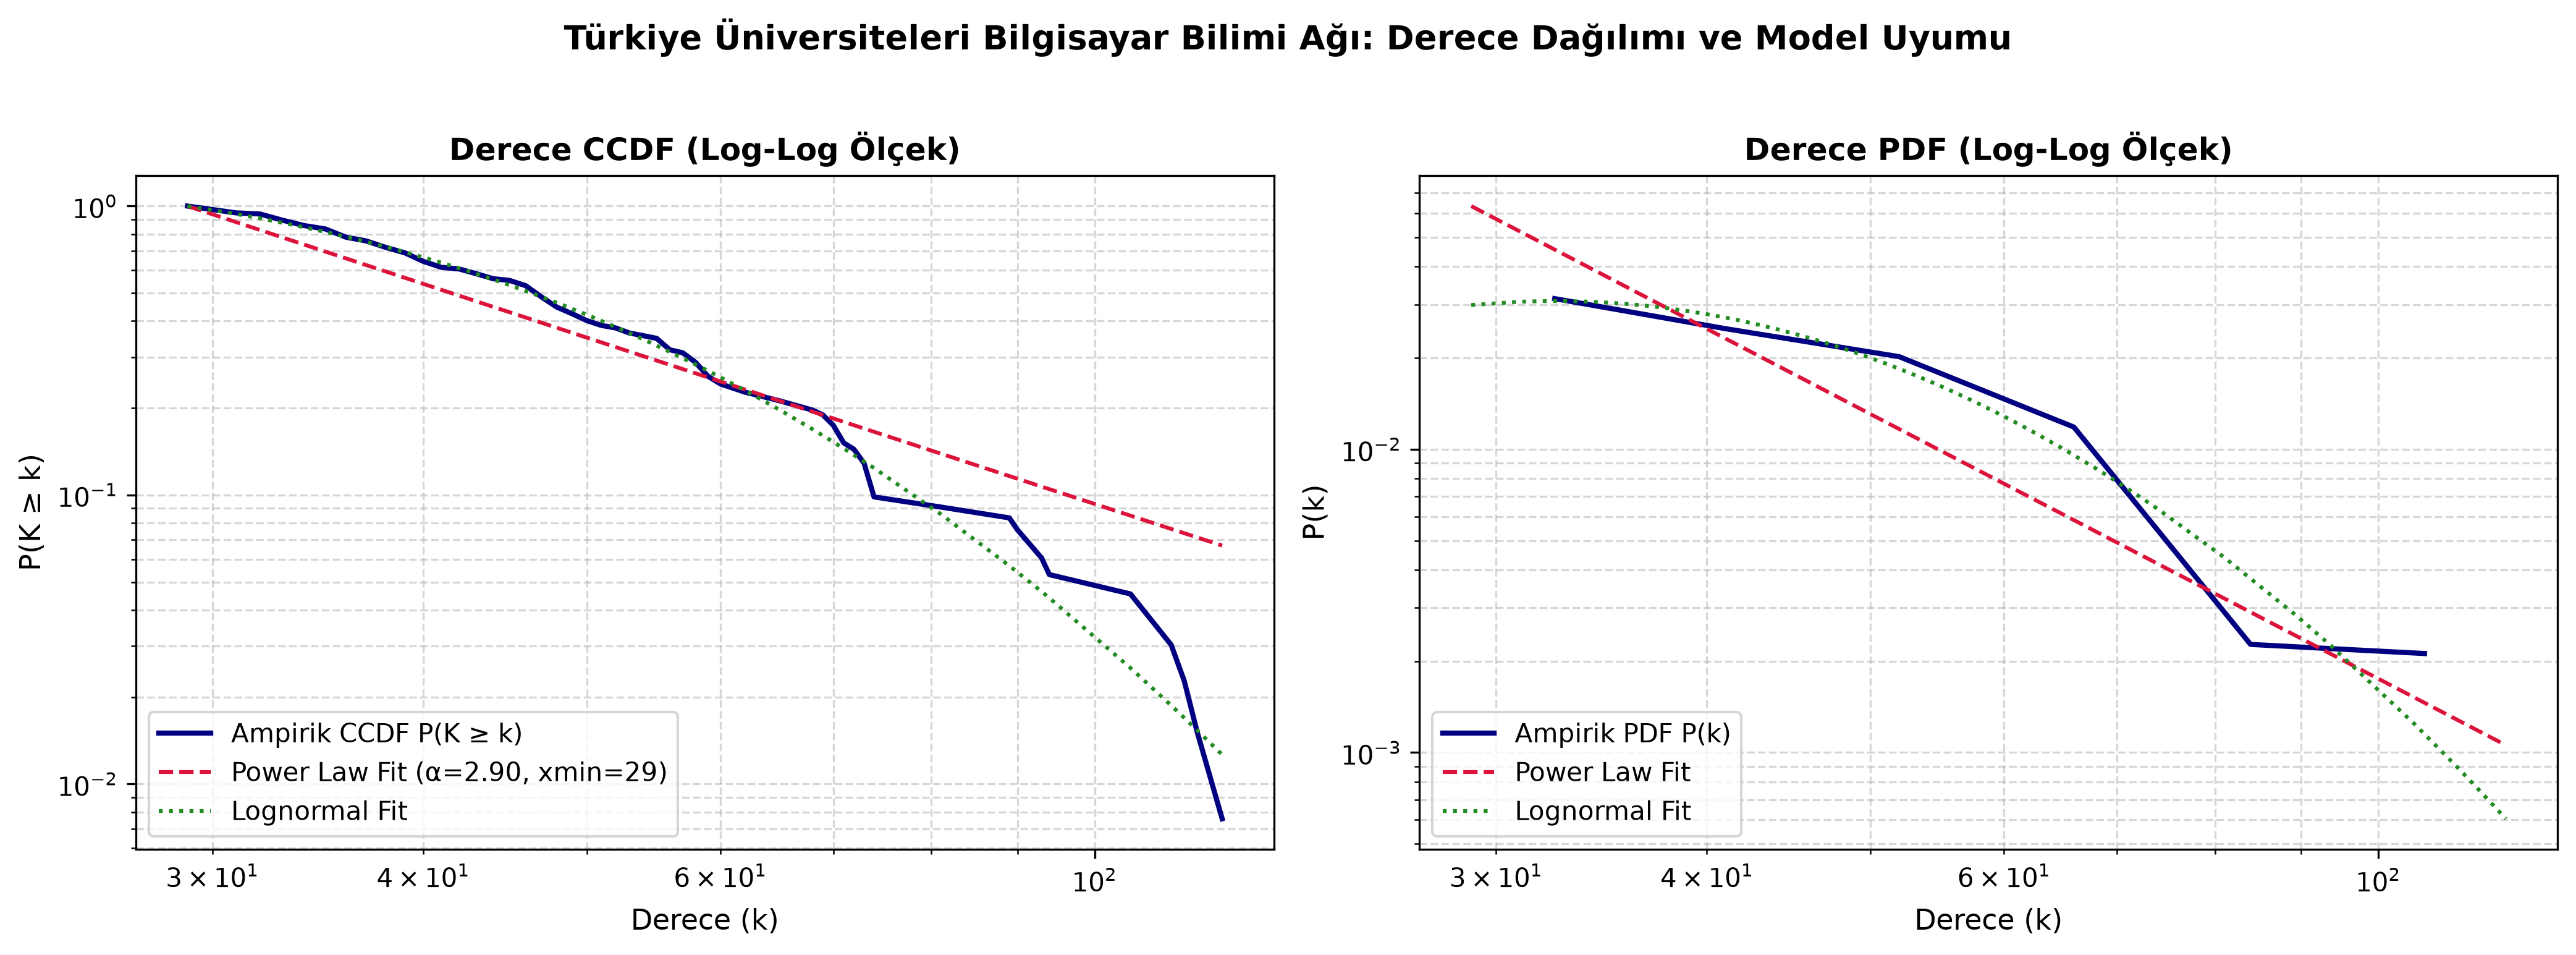

In [14]:
degrees = [d for _, d in G_b1.degree()]
pw_res = fit_powerlaw_distribution(degrees, output_plot_path="../reports/generated/degree_distribution_powerlaw.png")

print(f"Power Law Alpha: {pw_res["alpha"]:.4f}")
print(f"Minimum Eşik (xmin): {pw_res["xmin"]}")
print(f"Standart Hata (sigma): {pw_res["sigma"]:.4f}")
print(f"Üstel Modele Karşı R: {pw_res["comparison"]["vs_exponential"]["R"]:.3f} (p={pw_res["comparison"]["vs_exponential"]["p_value"]:.2e})")
print(f"Log-Normal Modele Karşı R: {pw_res["comparison"]["vs_lognormal"]["R"]:.3f} (p={pw_res["comparison"]["vs_lognormal"]["p_value"]:.4f})")
print(f"Saf Güç Yasası Destekleniyor mu?: {pw_res["comparison"]["supports_pure_power_law"]}")

# Üretilen grafiği göster
Image("../reports/generated/degree_distribution_powerlaw.png")

## 4. Topluluk Tespiti: Louvain ve Leiden Kararlılık Analizi
- 10 farklı sabit tohum (seed) ile tekrarlanabilir çalıştırma.
- NMI (Normalized Mutual Information) ve ARI (Adjusted Rand Index) metrikleriyle kararlılık ölçümü.
- En büyük 5 topluluğun hub kurumları ve Ege Bölgesi dağılımı.

In [15]:
comm_res = analyze_communities(G_b1, inst_metadata_df=df_b1, seeds=SEEDS_10)

print(f"Louvain Ortalama Topluluk Sayısı: {comm_res["summary"]["louvain"]["num_communities_mean"]:.1f}, Q: {comm_res["summary"]["louvain"]["modularity_mean"]:.4f}")
print(f"Louvain Kararlılık: NMI={comm_res["summary"]["louvain"]["stability"]["nmi_mean"]:.4f}, ARI={comm_res["summary"]["louvain"]["stability"]["ari_mean"]:.4f}")
print(f"Leiden  Ortalama Topluluk Sayısı: {comm_res["summary"]["leiden"]["num_communities_mean"]:.1f}, Q: {comm_res["summary"]["leiden"]["modularity_mean"]:.4f}")
print(f"Leiden  Kararlılık: NMI={comm_res["summary"]["leiden"]["stability"]["nmi_mean"]:.4f}, ARI={comm_res["summary"]["leiden"]["stability"]["ari_mean"]:.4f}")
print(f"İki Algoritma Arası Mutabakat: NMI={comm_res["summary"]["cross_algorithm_agreement"]["nmi"]:.4f}, ARI={comm_res["summary"]["cross_algorithm_agreement"]["ari"]:.4f}")

print("\n--- En Büyük Topluluklar ve Hub Kurumları ---")
display(comm_res["top_clusters_df"])

Louvain Ortalama Topluluk Sayısı: 6.5, Q: 0.3394
Louvain Kararlılık: NMI=0.8171, ARI=0.8032
Leiden  Ortalama Topluluk Sayısı: 6.6, Q: 0.1416
Leiden  Kararlılık: NMI=0.8378, ARI=0.8374
İki Algoritma Arası Mutabakat: NMI=0.7845, ARI=0.7589

--- En Büyük Topluluklar ve Hub Kurumları ---


,community_id,size,ratio,internal_edge_weight,egean_institutions_count,top_hub_institutions,member_sample
0,0,51,0.274194,2326,0,"Yıldız Technical University, Istanbul Universi...","Mimar Sinan Güzel Sanatlar Üniversitesi, Işık ..."
1,1,43,0.231183,1248,0,"Karadeniz Technical University, Fırat Universi...","İskenderun Technical University, Malatya Turgu..."
2,2,30,0.161290,716,3,"Sakarya University, Anadolu University, Kocael...","Bilecik Şeyh Edebali Üniversitesi, Bursa Uluda..."
3,3,29,0.155914,570,1,"Selçuk University, Erciyes University, Akdeniz...","Antalya Bilim University, Selçuk University, A..."
4,4,20,0.107527,911,0,"Gazi University, Hacettepe University, Ankara ...","Kastamonu University, Başkent University, Anka..."


## 5. Null Model Analizi (100 Derece Korumalı Rastgele Ağ)
- `connected_double_edge_swap` ile derece dizisi %100 korunan 100 rastgele ağ üretilir.
- Ampirik ağın kümelenme ($C$), yol uzunluğu ($L$) ve modülerlik ($Q$) değerleri null dağılımla kıyaslanır.
- Z-skoru, ampirik $p$-değeri ve Small-Worldness katsayısı ($\\sigma$) hesaplanır.

In [16]:
# Hızlı interaktif görüntüleme için önceden üretilen 100 ağ sonuçları okunabilir ya da modülden çağrılabilir
null_summary_path = "../reports/generated/null_model_comparison.json"
with open(null_summary_path, "r", encoding="utf-8") as f:
    null_sum = json.load(f)

df_null = pd.read_csv("../reports/generated/null_model_comparison.csv")
display(df_null)

print(f"Küçük Dünya Katsayısı (sigma): {null_sum["small_worldness"]["sigma"]:.4f} (Small-World: {null_sum["small_worldness"]["is_small_world"]})")

,metric,observed,null_mean,null_std,z_score,empirical_p_value
0,Average Clustering Coefficient (C),0.443282,0.389768,0.00446,11.997658,0.009901
1,Average Shortest Path Length (L),1.829003,1.807900,0.00349,6.046506,0.009901
2,Louvain Modularity (Q),0.341372,0.163425,0.02165,8.219137,0.009901


Küçük Dünya Katsayısı (sigma): 1.1242 (Small-World: True)


## 6. Zorunlu İleri Yöntem: Çekim (Gravity) Modeli Regresyonu
- $\\binom{186}{2} = 17.205$ ikili üniversite çifti ($w=0$ sıfır iş birliği çiftleri eksiksiz dahil).
- Büyük daire (Haversine) mesafesi ve aynı şehir çakışmaları için $d_{eff} = d + 1.0\text{ km}$ düzeltmesi.
- Kurum büyüklüğü: 2020–2025 dönemi CS yayın hacmi (`period_cs_works_count`).
- Poisson ve Negative Binomial GLM modelleri, aşırı yayılım testi ve Ege Bölgesi ($BothEgean$) çekim faktörü.

In [17]:
with open("../reports/generated/gravity_model_results.json", "r", encoding="utf-8") as f:
    grav_results = json.load(f)

df_grav_summary = pd.read_csv("../reports/generated/gravity_model_summary.csv")
display(df_grav_summary)

print("\n--- Aşırı Yayılım (Overdispersion) ve Model Tavsiyesi ---")
print(f"Pearson Dispersiyon Oranı: {grav_results["poisson_model"]["pearson_dispersion_ratio"]:.2f}")
print(f"Aşırı Yayılım Tespit Edildi mi?: {grav_results["poisson_model"]["overdispersion_detected"]}")
print(f"Önerilen Model: {grav_results["synthesis"]["primary_model_recommendation"]}")
print(f"\nBilimsel Sonuç: {grav_results["synthesis"]["scientific_conclusion"]["distance_effect"]}")
print(f"Ege Bölgesi Etkisi: {grav_results["synthesis"]["scientific_conclusion"]["egean_effect"]}")

,term,poisson_coef,poisson_se,poisson_p,poisson_exp_coef,nb_coef,nb_se,nb_p,nb_exp_coef
0,Intercept,-7.192000,0.089817,0.000000e+00,0.000753,-7.183778,0.134034,0.000000e+00,0.000759
1,log_size_i,0.748314,0.010888,0.000000e+00,2.113434,0.743308,0.016684,0.000000e+00,2.102880
2,log_size_j,0.756672,0.010170,0.000000e+00,2.131171,0.778623,0.015798,0.000000e+00,2.178471
3,log_distance,-0.267196,0.003429,0.000000e+00,0.765523,-0.287428,0.006483,0.000000e+00,0.750190
4,both_egean,0.845797,0.061069,1.276445e-43,2.329833,0.826376,0.137001,1.620444e-09,2.285022



--- Aşırı Yayılım (Overdispersion) ve Model Tavsiyesi ---
Pearson Dispersiyon Oranı: 4.67
Aşırı Yayılım Tespit Edildi mi?: True
Önerilen Model: Negative Binomial GLM

Bilimsel Sonuç: Mesafe katsayısı negatif ve istatistiksel olarak anlamlıdır (β=-0.2672, p < 0.001). Coğrafi mesafe arttıkça iki üniversite arasındaki iş birliği olasılığı ve hacmi azalmaktadır.
Ege Bölgesi Etkisi: Her iki kurumun da Ege Bölgesi'nde olması iş birliğini pozitif etkilemektedir (β=0.8458, p=1.2764e-43). Bölgesel yakınlık Türkiye genelindeki mesafe etkisinin ötesinde ek bir çekim faktörüdür.


## 7. Türkiye Coğrafi İş Birliği Haritası
Üretilen etkileşimli harita `reports/generated/turkey_collaboration_map.html` dosyası olarak kaydedilmiştir. Folium tabanlı bu haritada şehir içi koordinat çakışmaları açısal dağıtım (jitter) ile çözülmüş, düğüm boyutları derece ile ölçeklendirilmiş ve güçlü iş birlikleri ($w \ge 5$) görselleştirilmiştir.

In [18]:
print("Harita dosya yolu: reports/generated/turkey_collaboration_map.html")
print("Harita boyutu:", os.path.getsize("../reports/generated/turkey_collaboration_map.html"), "bayt")
# Notebook içinde küçük bir iframe ile gösterme seçeneği:
HTML("<iframe src=""../reports/generated/turkey_collaboration_map.html"" width=""100%"" height=""500px""></iframe>")

Harita dosya yolu: reports/generated/turkey_collaboration_map.html
Harita boyutu: 1007999 bayt


/home/ahmetcan/turkiye-universiteleri-isbirligi-agi/venv/lib/python3.12/site-packages/IPython/core/display.py:448: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")
